# 06 - The full benchmark: v4 and v9 against QUANT + ExtraTrees (142 datasets x 30 resamples)

Notebook 04 found the cheapest good TabPFN setting, **v4**: the lean extractor `quant_tabpfn.py` (QUANT-style
features, about 450 per run), ANOVA then ExtraTrees pick the 200 given to TabPFN, 2 passes, TabPFN's model built
once. Notebook 05 built the supervised extractor; its last version, **v9**, picks at most 200 features per dataset
from a pool of candidates (QUANT's four views with a fifth of QUANT's quantiles, median kept; lag-d views chosen per
dataset; catch22; pattern templates). This notebook runs both on the paper's full benchmark and compares them with
QUANT + ExtraTrees, the original method. The comparison with the paper's published results is in notebook 01; the
earlier versions, and TabPFN on QUANT's own features, are compared on the small and medium datasets in notebooks
02 to 05.

| Name | What it is | File |
|---|---|---|
| **QUANT + ExtraTrees (v1)** | our run of the original method, with timers and seed 0 (notebook 01), one CPU core | `results/v1_ucr142_onecore-cpu.csv` |
| **QUANT + ExtraTrees, all cores (v1)** | the same method, seed and splits on all CPU cores, for the time comparison; its accuracies are identical to the one-core run (4,260 of 4,260) | `results/v1_ucr142_allcores-cpu.csv` |
| **v4 (cheap TabPFN)** | the lean extractor, 2 passes x 200 features (ANOVA + ExtraTrees), model cache, all CPU cores + GPU | `results/v4_tabpfn-e2f200-both_ucr142_allcores-gpu.csv` |
| **v9 (supervised extractor)** | the extractor picks at most 200 features itself (ANOVA + ExtraTrees selection without near-copies, the budget filled up with finer pieces down to 1/16), 2 passes, model cache, all CPU cores + GPU | `results/v9_tabpfn-e2f200_ucr142_allcores-gpu.csv` |

| Setting | Value |
|---|---|
| datasets | the 142 datasets of the paper (`original/code/ucr142.txt`) |
| resamples | 30: 0 = the original split, 1-29 = the bake-off redux splits (`data/indices`); the same splits for every result |
| v4 | `improvedQuant/features/run.py --quant tabpfn -m 4 --quantiles 2 --lags 4,16 --tabpfn_rank both --tabpfn_estimators 2 --tabpfn_features 200 --tabpfn_cache` |
| v9 | `improvedQuant/features/run.py --quant supervised --catch22 --templates --lags auto --fill_budget --c22_shorten --supervised_rank both --supervised_max_depth 5 --quantile_fraction 0.2 --supervised_budget 200 --tabpfn_estimators 2 --tabpfn_features 200 --tabpfn_cache` |
| seed | 0 |

**How the files are produced:** see `experiments.md`, sections v1, v4 and v9 (v4 about 3.5 hours, v9 about 4.7 hours,
QUANT + ExtraTrees on all cores about 1.7 hours; all 4,260 runs of each finished).

- **Section 2** - mean accuracy and mean rank of the three results.
- **Section 3** - per dataset: v4 and v9 vs QUANT + ExtraTrees, v9 vs v4, and the significance tests.
- **Section 4** - time per run.

All results are shown as plots; times are in seconds on linear axes.

## 1. Settings and data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# the shared names, colours, plot style and loading of all notebooks: notebooks/common.py
from common import BETTER, EQUAL, MUTED, REPO, RESULTS_DIR, TEXT, VERSION_COLORS, WORSE, load_runs, signed, style, wdl_counts

style()
NAMES = {"v1": "QUANT + ExtraTrees (v1)", "v4": "v4 (cheap TabPFN)", "v9": "v9 (supervised extractor)"}
RESULT_COLORS = {"v1": VERSION_COLORS["v1"], "v1 all cores": "#9cc3ef", "v4": "#eda100", "v9": "#8e1b4f"}  # v4, v9: as notebook 05
DATASETS = (REPO / "original" / "code" / "ucr142.txt").read_text().split()   # the 142 datasets of the paper

v1_runs = load_runs(RESULTS_DIR / "v1_ucr142_onecore-cpu.csv")      # one row per run
v1_all_runs = load_runs(RESULTS_DIR / "v1_ucr142_allcores-cpu.csv")  # the same method on all CPU cores
v4_runs = load_runs(RESULTS_DIR / "v4_tabpfn-e2f200-both_ucr142_allcores-gpu.csv")   # notebook 04
v9_runs = load_runs(RESULTS_DIR / "v9_tabpfn-e2f200_ucr142_allcores-gpu.csv")        # notebook 05

def wide(runs):
    """One row per dataset (in the order of the paper's list), one column per resample."""
    return runs.pivot(index="dataset", columns="resample", values="accuracy").loc[DATASETS]

ACCURACY = {"v1": wide(v1_runs), "v4": wide(v4_runs), "v9": wide(v9_runs)}
MEAN = pd.DataFrame({name: table.mean(axis=1) for name, table in ACCURACY.items()})   # mean of the 30 per dataset
same = (wide(v1_all_runs) == ACCURACY["v1"]).sum().sum()
print(f"QUANT + ExtraTrees, all cores vs one core: identical accuracy in {same} of {ACCURACY['v1'].size} runs")
print(f"runs finished: v4 {(v4_runs['status'] == 'ok').sum()} of {len(v4_runs)}, "
      f"v9 {(v9_runs['status'] == 'ok').sum()} of {len(v9_runs)}, "
      f"v1 {(v1_runs['status'] == 'ok').sum()} of {len(v1_runs)}; missing values: "
      f"{sum(int(t.isna().sum().sum()) for t in ACCURACY.values())}")

QUANT + ExtraTrees, all cores vs one core: identical accuracy in 4260 of 4260 runs
runs finished: v4 4260 of 4260, v9 4260 of 4260, v1 4260 of 4260; missing values: 0


## 2. Mean accuracy and mean rank

Left: the mean accuracy over the 142 datasets (each dataset = the mean of its 30 resamples); QUANT + ExtraTrees on
all CPU cores gives exactly the same accuracies as on one core (section 1). Right: the mean rank: for every dataset
the three results are ranked 1 (best) to 3, ties share the rank.

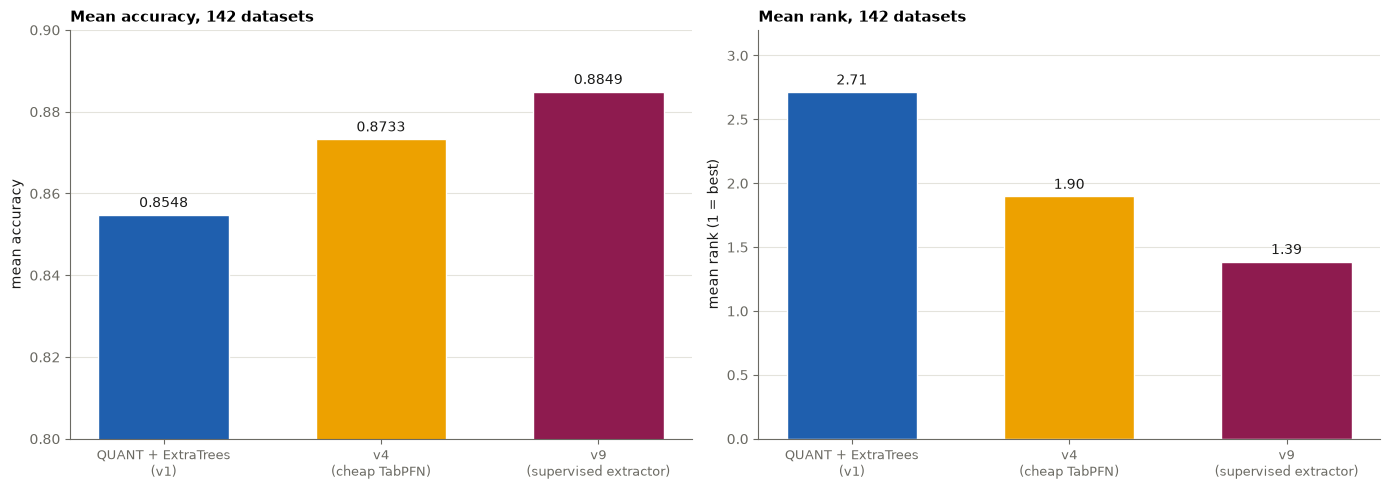

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
bars = ax.bar(range(len(NAMES)), MEAN[list(NAMES)].mean(), 0.6, color=[RESULT_COLORS[n] for n in NAMES],
              edgecolor="white")
ax.bar_label(bars, fmt="{:.4f}", padding=3, fontsize=10, color=TEXT)
ax.set_xticks(range(len(NAMES)), [NAMES[n].replace(" (", "\n(") for n in NAMES], fontsize=9)
ax.set_ylim(0.80, 0.90)
ax.set_ylabel("mean accuracy")
ax.set_title("Mean accuracy, 142 datasets", loc="left")

ax = axes[1]
ranks = MEAN.rank(axis=1, ascending=False).mean()       # 1 = the most accurate on a dataset
bars = ax.bar(range(len(NAMES)), [ranks[n] for n in NAMES], 0.6, color=[RESULT_COLORS[n] for n in NAMES],
              edgecolor="white")
ax.bar_label(bars, fmt="{:.2f}", padding=3, fontsize=10, color=TEXT)
ax.set_xticks(range(len(NAMES)), [NAMES[n].replace(" (", "\n(") for n in NAMES], fontsize=9)
ax.set_ylim(0, 3.2)
ax.set_ylabel("mean rank (1 = best)")
ax.set_title("Mean rank, 142 datasets", loc="left")
fig.tight_layout()
plt.show()

Note: the accuracy axis starts at 0.80, to make the differences visible.

## 3. Per dataset: v4 and v9 vs QUANT + ExtraTrees, and v9 vs v4

Our runs on all 142 datasets, the same splits; one row per comparison. Left: one point per dataset (the means of
its 30 resamples); above the diagonal the first-named result is more accurate. Right: the change on every dataset,
sorted. The Wilcoxon signed-rank test asks whether the changes are centred on 0 (no difference); with a p-value
below 0.05 the difference is unlikely to be chance.

v4 (cheap TabPFN) vs QUANT + ExtraTrees (v1), 142 datasets: better 111, equal 8, worse 23; mean change +0.019; Wilcoxon p = 2.0e-12
  largest gains: PigAirwayPressure +0.460, ChlorineConcentration +0.173, InlineSkate +0.156, Tools +0.102, AllGestureWiimoteYEq +0.098
  largest losses: ShapeletSim -0.075, ToeSegmentation2 -0.058, ToeSegmentation1 -0.049, BeetleFly -0.040, HouseTwenty -0.038


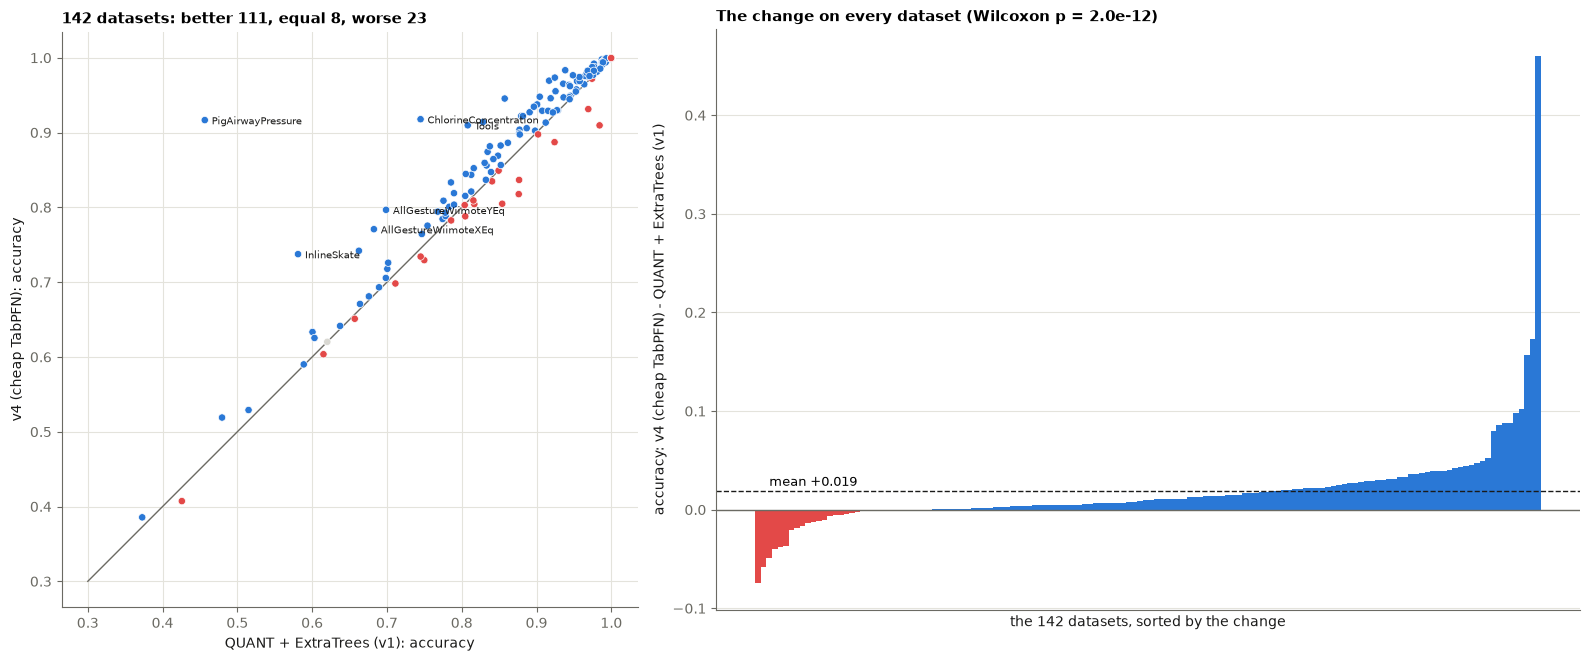

v9 (supervised extractor) vs QUANT + ExtraTrees (v1), 142 datasets: better 126, equal 3, worse 13; mean change +0.030; Wilcoxon p = 1.9e-21
  largest gains: PigAirwayPressure +0.481, PigCVP +0.181, ChlorineConcentration +0.151, InlineSkate +0.150, AllGestureWiimoteXEq +0.115
  largest losses: Colposcopy -0.029, MoteStrain -0.016, Herring -0.014, DistalPhalanxOutlineAgeGroup -0.009, Chinatown -0.005


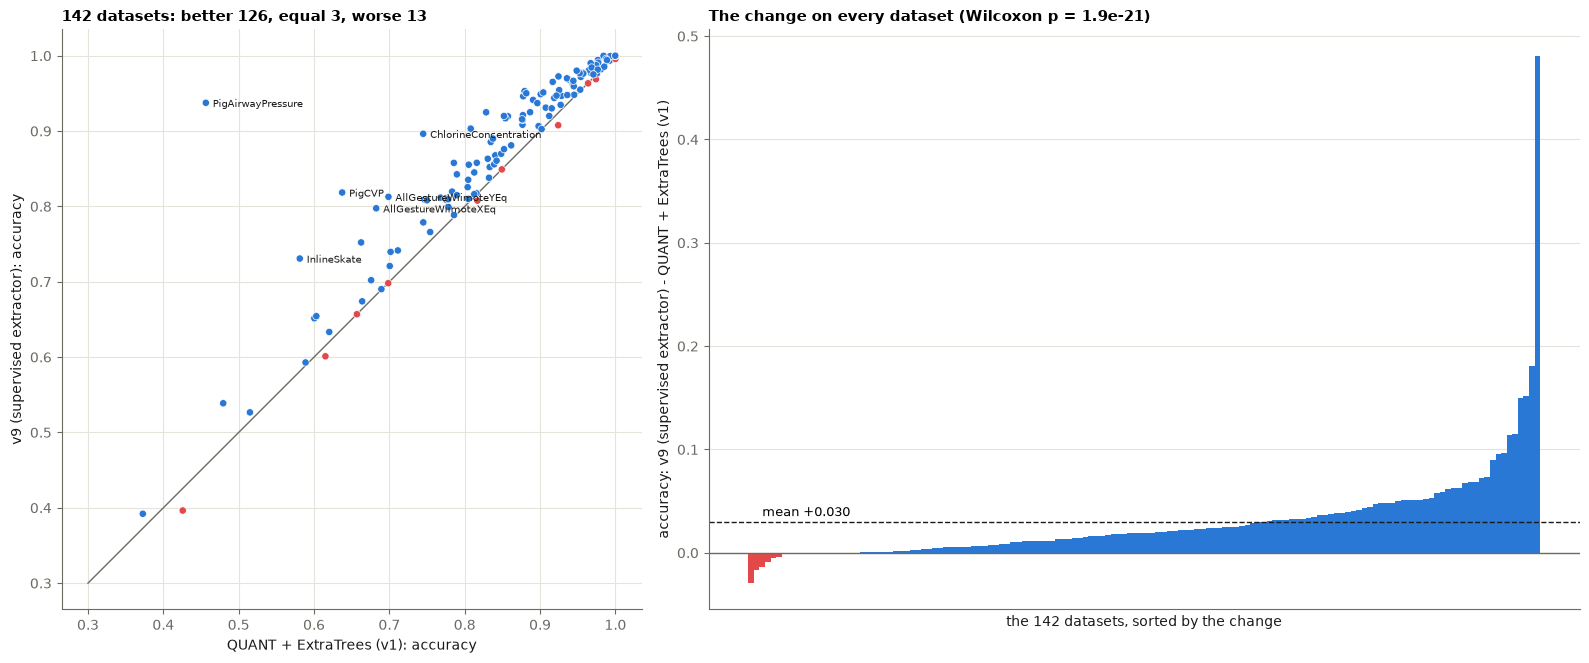

v9 (supervised extractor) vs v4 (cheap TabPFN), 142 datasets: better 99, equal 5, worse 38; mean change +0.012; Wilcoxon p = 3.1e-11
  largest gains: PigCVP +0.177, ToeSegmentation1 +0.112, ToeSegmentation2 +0.098, ShapeletSim +0.090, RefrigerationDevices +0.079
  largest losses: SemgHandMovementCh2 -0.026, ChlorineConcentration -0.021, BirdChicken -0.015, Colposcopy -0.011, Earthquakes -0.010


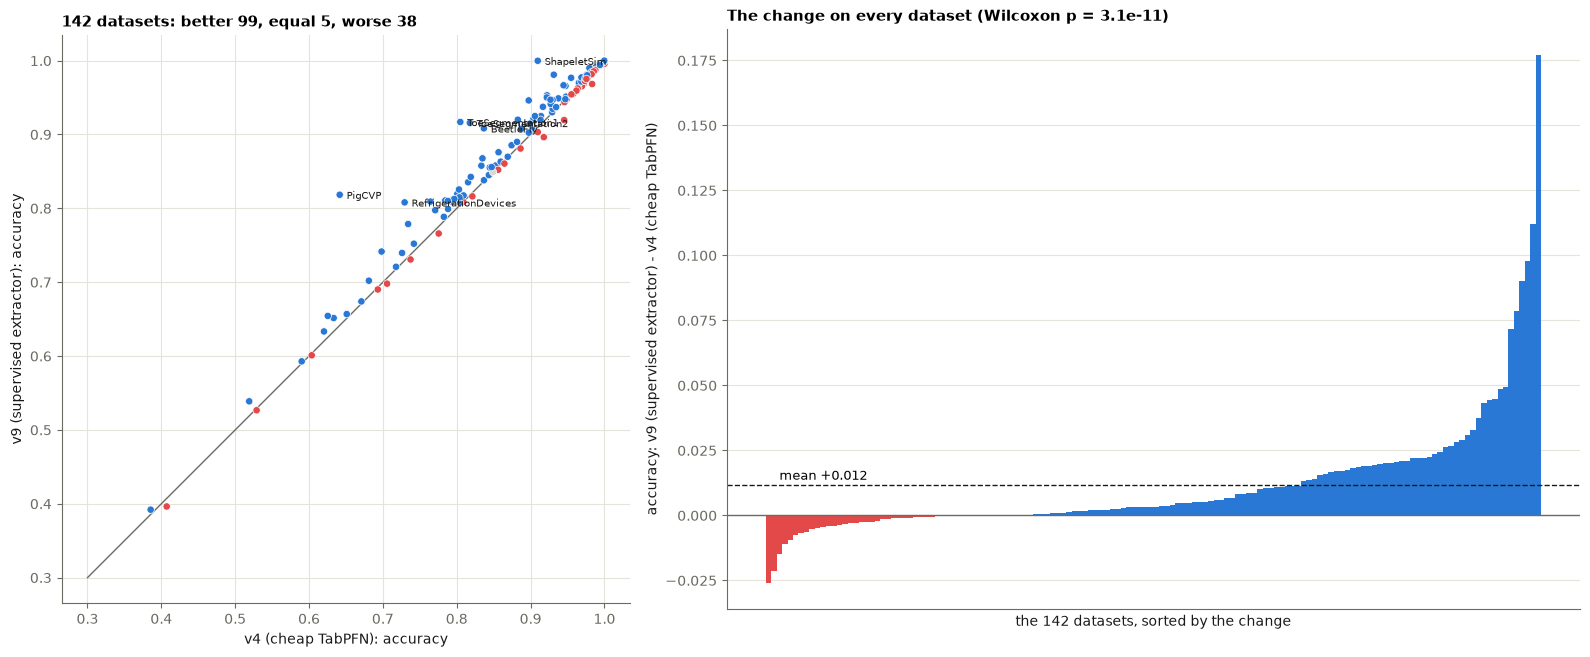

In [3]:
def compare(a, b):
    """The per-dataset comparison of result a against result b (all 142 datasets): prints and one row of plots."""
    change = MEAN[a] - MEAN[b]
    better, equal, worse = wdl_counts(change)
    p_value = stats.wilcoxon(MEAN[a], MEAN[b]).pvalue
    print(f"{NAMES[a]} vs {NAMES[b]}, 142 datasets: better {better}, equal {equal}, worse {worse}; "
          f"mean change {signed(change.mean())}; Wilcoxon p = {p_value:.1e}")
    print("  largest gains:", ", ".join(f"{n} {signed(x)}" for n, x in change.sort_values().tail(5)[::-1].items()))
    print("  largest losses:", ", ".join(f"{n} {signed(x)}" for n, x in change.sort_values().head(5).items()))
    colors = [BETTER if x > 1e-12 else WORSE if x < -1e-12 else EQUAL for x in change]
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.5]})
    ax = axes[0]
    ax.plot([0.3, 1.0], [0.3, 1.0], color=MUTED, linewidth=1, zorder=1)    # the diagonal: equal accuracy
    ax.scatter(MEAN[b], MEAN[a], s=28, c=colors, edgecolor="white", linewidth=0.5, zorder=3)
    for name in change.abs().sort_values().index[-6:]:                     # the largest changes, named
        ax.annotate(name, (MEAN.loc[name, b], MEAN.loc[name, a]), xytext=(5, -3), textcoords="offset points",
                    fontsize=7.5, color=TEXT)
    ax.set_xlabel(f"{NAMES[b]}: accuracy")
    ax.set_ylabel(f"{NAMES[a]}: accuracy")
    ax.set_title(f"142 datasets: better {better}, equal {equal}, worse {worse}", loc="left")
    ax.grid(True, axis="both")
    ax.set_aspect("equal")

    ax = axes[1]
    order = change.sort_values()
    ax.bar(range(len(order)), order, 1.0, color=[BETTER if x > 1e-12 else WORSE if x < -1e-12 else EQUAL for x in order])
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.axhline(change.mean(), color=TEXT, linewidth=1, linestyle="--")
    ax.annotate(f"mean {signed(change.mean())}", (2, change.mean()), xytext=(0, 4), textcoords="offset points", fontsize=9)
    ax.set_xticks([])
    ax.set_xlabel("the 142 datasets, sorted by the change")
    ax.set_ylabel(f"accuracy: {NAMES[a]} - {NAMES[b]}")
    ax.set_title(f"The change on every dataset (Wilcoxon p = {p_value:.1e})", loc="left")
    fig.tight_layout()
    plt.show()

compare("v4", "v1")
compare("v9", "v1")
compare("v9", "v4")

## 4. Time per run

The mean time per run (transforms + feature selection + fit + predict) of every dataset, against its size. QUANT +
ExtraTrees ran twice, on one CPU core (as in the paper's timing claim) and on all CPU cores; v4 and v9 ran on all CPU
cores and the GPU. The all-cores runs are the fair comparison (same machine, same cores); TabPFN also
uses the GPU, which ExtraTrees cannot.

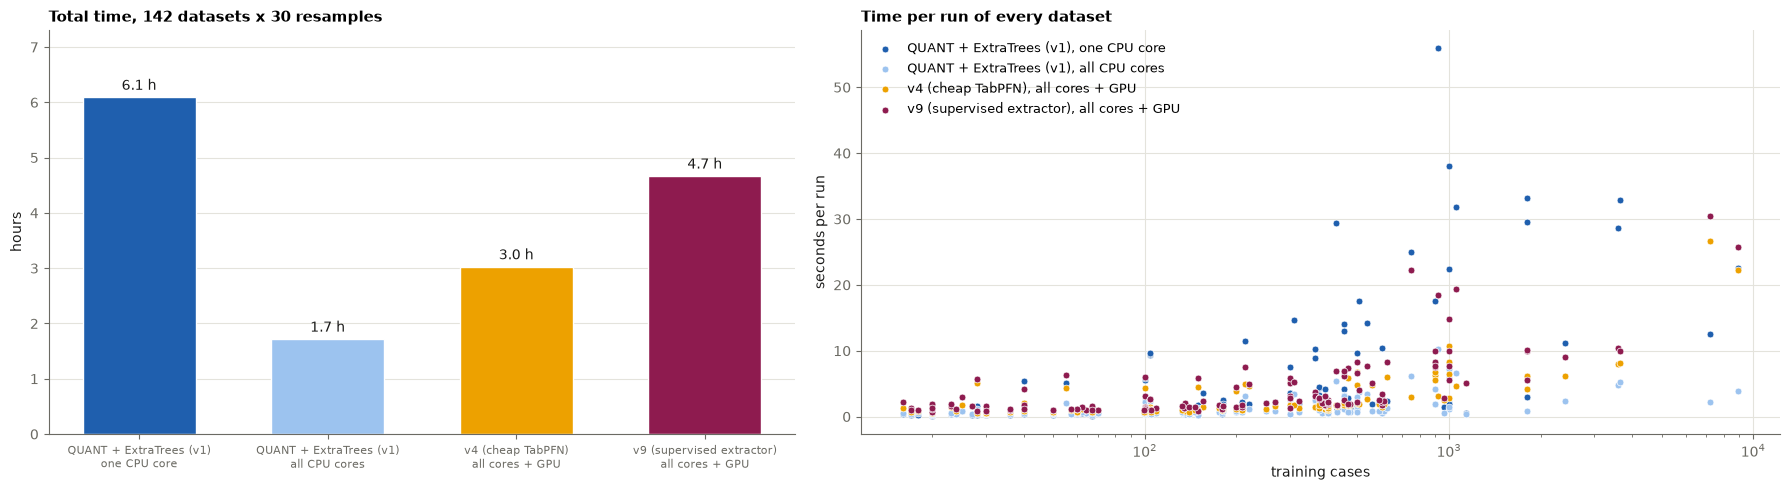

In [4]:
n_train = v4_runs.groupby("dataset")["n_train"].first()               # training cases of every dataset
RUNS = {"v1": v1_runs, "v1 all cores": v1_all_runs, "v4": v4_runs, "v9": v9_runs}
LABELS = {"v1": "QUANT + ExtraTrees (v1)\none CPU core", "v1 all cores": "QUANT + ExtraTrees (v1)\nall CPU cores",
          "v4": "v4 (cheap TabPFN)\nall cores + GPU", "v9": "v9 (supervised extractor)\nall cores + GPU"}
time = pd.DataFrame({name: runs.groupby("dataset")["total_time"].mean() for name, runs in RUNS.items()}).loc[DATASETS]
fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1.3, 1.6]})
ax = axes[0]
totals = [runs["total_time"].sum() / 3600 for runs in RUNS.values()]
bars = ax.bar(range(len(RUNS)), totals, 0.6, color=[RESULT_COLORS[n] for n in RUNS], edgecolor="white")
ax.bar_label(bars, fmt="{:.1f} h", padding=3, fontsize=10, color=TEXT)
ax.set_xticks(range(len(RUNS)), [LABELS[n] for n in RUNS], fontsize=8)
ax.set_ylim(0, max(totals) * 1.2)
ax.set_ylabel("hours")
ax.set_title("Total time, 142 datasets x 30 resamples", loc="left")

ax = axes[1]
for name in RUNS:
    ax.scatter(n_train[time.index], time[name], s=24, color=RESULT_COLORS[name], edgecolor="white",
               linewidth=0.5, label=LABELS[name].replace("\n", ", "), zorder=3)
ax.set_xscale("log")
ax.set_xlabel("training cases")
ax.set_ylabel("seconds per run")
ax.set_title("Time per run of every dataset", loc="left")
ax.grid(True, axis="both")
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 5. Conclusions

**v9, the supervised extractor of notebook 05, is the most accurate of the three.**
- Mean accuracy 0.8849 on all 142 datasets, against 0.8733 for v4 and 0.8548 for QUANT + ExtraTrees; mean rank 1.39,
  against 1.90 (v4) and 2.71 (QUANT + ExtraTrees).
- **Against QUANT + ExtraTrees:** better on 126 of 142 datasets, equal on 3, worse on 13 (+0.030 on average,
  Wilcoxon p = 2e-21). The largest gains are PigAirwayPressure +0.481 (52 classes, 104 training cases), PigCVP
  +0.181, ChlorineConcentration +0.151 and InlineSkate +0.150; the losses are at most -0.029 (Colposcopy), then
  MoteStrain -0.016 and Herring -0.014: datasets with few training cases.
- **Against v4:** better on 99, equal on 5, worse on 38 (+0.012, p = 3e-11). The datasets v4 lost most on are among
  the largest gains (ToeSegmentation1 +0.112, ToeSegmentation2 +0.098, ShapeletSim +0.090, after PigCVP +0.177),
  thanks to catch22 and the pattern templates; the largest losses are SemgHandMovementCh2 -0.026 and
  ChlorineConcentration -0.021.

**v4, the cheap TabPFN of notebook 04, already beats QUANT + ExtraTrees clearly:** 0.8733 against 0.8548 (+0.019),
better on 111 of 142 datasets, equal on 8, worse on 23 (p = 2e-12). Its gains can be large (PigAirwayPressure
+0.460, ChlorineConcentration +0.173, InlineSkate +0.156, Tools +0.102); its losses are at most -0.075
(ShapeletSim, ToeSegmentation2 and 1, BeetleFly, HouseTwenty): small two-class datasets whose class depends on a
short local pattern (notebook 05, section 2), which v9 fixes.

**Time:** on the same CPU cores QUANT + ExtraTrees needs 1.7 hours for all 4,260 runs (6.1 hours on one core, with
exactly the same accuracies), v4 3.0 hours and v9 4.7 hours, with the GPU's help: 1.8 and 2.7 times the original
method. Half of the datasets take 1.5 s per run or less with v4 and about 2.2 s or less with v9; the largest
(ElectricDevices, Crop, and for v9 also AsphaltPavementTypeUniEq and AsphaltRegularityUniEq) 19 to 31 s.

Caveats: one seed per resample; v4 and v9 were developed on at most 20 of the 142 datasets (the small and medium
smoke lists and the worst datasets of earlier versions), too few to explain the gains; TabPFN is a pretrained model,
QUANT + ExtraTrees learns from each dataset alone.